We need to put some results for the department seminar presentation slide. Professor said I should make DO-Nutrient diagram and also T-S diagram with colored dots to show the DO value.

In [1]:
# Imports
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as colors

In [2]:
# In [2]: Load and Prepare Data
# Load the pre-processed data
merged_gdf = pd.read_feather('../data/processed/merged_gdf.feather', use_threads=False)
merged_gdf = gpd.GeoDataFrame(merged_gdf, geometry=gpd.points_from_xy(merged_gdf.longitude, merged_gdf.latitude), crs='EPSG:4326')

# Filter summer bottom do data
summer_bottom_df = merged_gdf[
    (merged_gdf['season'] == 'Summer') &
    (merged_gdf['saisuipoin'] == 2)
].dropna(subset=['do_']).copy()

print(summer_bottom_df.head())

      uniqueid zettaicode locationna wancode prefectuei  watercode renban  \
4   0000001734   00002811      兵庫県11      03         28        301     11   
12  0000001742   00002823      兵庫県23      03         28        301     23   
19  0000001678   00000272       大阪府2      03         27        301      2   
27  0000001686   00000275       大阪府5      03         27        301      5   
35  0000001694   00002725      大阪府25      03         27        301     25   

    nendo  survey_ym  surveyyear  ...   doc  doc2  dataflag  scale  \
4    1981 1981-06-01        1981  ...  None   0.0         1     -1   
12   1981 1981-06-01        1981  ...  None   0.0         1     -1   
19   1981 1981-06-01        1981  ...  None   0.0         1     -1   
27   1981 1981-06-01        1981  ...  None   0.0         1     -1   
35   1981 1981-06-01        1981  ...  None   0.0         1     -1   

                      geometry  year   watermass_name   division  \
4     POINT (135.33056 34.695)  1981  Seto Inlan

In [3]:
print(summer_bottom_df['division'].unique())
print(summer_bottom_df.columns)

['Osaka Bay' 'Harima Nada' 'Iyo Nada' 'Suo Nada' 'Bisan Seto' 'Bingo Nada'
 'Bungo Channel' 'Hibiki Nada' 'Kii Channel' 'Aki Nada' 'Hiroshima Bay'
 'Hiuchi Nada']
Index(['uniqueid', 'zettaicode', 'locationna', 'wancode', 'prefectuei',
       'watercode', 'renban', 'nendo', 'survey_ym', 'surveyyear', 'surveymont',
       'surveyday', 'surveyhour', 'surveymini', 'saisuipoin', 'latitude',
       'longitude', 'weather', 'cloud', 'fuko', 'fusoku', 'temp', 'color',
       'saisuidept', 'depth', 'clearness', 'wtemp', 'ph', 'ph2', 'do_', 'do_2',
       'salt', 'salt2', 'cod', 'cod2', 'rcod', 'rcod2', 'nh4n', 'nh4n2',
       'no2n', 'no2n2', 'no3n', 'no3n2', 'tn', 'tn2', 'po4p', 'po4p2', 'tp',
       'tp2', 'chlorophyl', 'chloroph_1', 'feiochin', 'feiochin2', 'toc',
       'toc2', 'doc', 'doc2', 'dataflag', 'scale', 'geometry', 'year',
       'watermass_name', 'division', 'details', 'season'],
      dtype='object')


This dataset has the nutrient columns ```['tn', 'tp', 'po4p', 'cod']``` which represents total nitrogen (TN), total phosphorus (TP), phosphate (PO4-P), and chemical oxygen demand (COD).

In [4]:
# Filter the dataframe based on the target areas
target_division = ['Osaka Bay', 'Hiroshima Bay','Hiuchi Nada', 'Harima Nada']
target_df = summer_bottom_df[summer_bottom_df['division'].isin(target_division)].copy()

In [5]:
# print range of each nutrient column
nutrient_cols = ['tn', 'tp', 'po4p', 'cod']

nutrient_ranges = {}
for col in nutrient_cols:
    s = pd.to_numeric(target_df[col], errors='coerce').dropna()
    if len(s) == 0:
        nutrient_ranges[col] = (None, None)
    else:
        nutrient_ranges[col] = (float(s.min()), float(s.max()))

do_s = pd.to_numeric(target_df['do_'], errors='coerce').dropna()
do_range = (float(do_s.min()), float(do_s.max())) if len(do_s) else (None, None)


In [32]:
# SELECT NUTRIENT BELOW
# nutrient_col = 'tn'
# nutrient_col = 'tp'
# nutrient_col = 'po4p'
nutrient_col = 'cod'
do_col = 'do_'

target_df[nutrient_col] = pd.to_numeric(target_df[nutrient_col], errors='coerce')
target_df[do_col] = pd.to_numeric(target_df[do_col], errors='coerce')

labels = {
    'tn': 'Total Nitrogen (mg/L)',
    'tp': 'Total Phosphorus (mg/L)',
    'po4p': 'Phosphate-P (mg/L)',
    'cod': 'COD (mg/L)',
    'do_': 'Dissolved Oxygen (mg/L)'
}

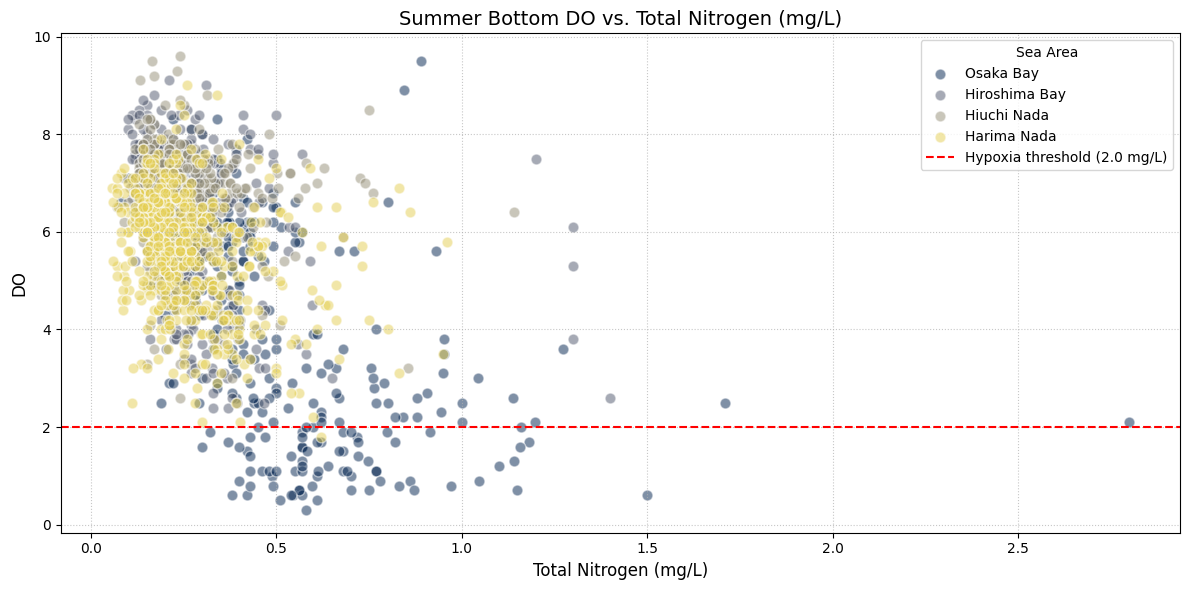

In [ ]:
plt.figure(figsize=(12,6))
colors = cm.cividis(np.linspace(0, 0.9, len(target_division)))

for i, area in enumerate(target_division):
    # Subset data for this specific area
    subset = target_df[target_df['division'] == area]
    
    plt.scatter(
        subset[nutrient_col], 
        subset['do_'], 
        label=area,      # This ensures it shows up in the legend
        color=colors[i], # Assign unique color
        alpha=0.5,       # Transparency
        edgecolors='w',  # White edge makes dots stand out
        s=60             # Dot size
    )

# hypoxia treshold reference line (2mg/L)
plt.axhline(y=2.0, color='red', linestyle='--', linewidth=1.5, label='Hypoxia threshold (2.0 mg/L)')

# get axis and set ranges if available
ax = plt.gca()

# X range from nutrient_ranges
xr = nutrient_ranges.get(nutrient_col, (None, None))
if xr[0] is not None and xr[1] is not None:
    xmin, xmax = xr
    if xmin == xmax:
        # small symmetric padding if all values equal
        pad = abs(xmin) * 0.05 if xmin != 0 else 0.05
        ax.set_xlim(xmin - pad, xmax + pad)
    else:
        pad = (xmax - xmin) * 0.05  # 5% margin
        ax.set_xlim(xmin - pad, xmax + pad)

# Y range from do_range
yr = do_range
if yr[0] is not None and yr[1] is not None:
    ymin, ymax = yr
    if ymin == ymax:
        pad = abs(ymin) * 0.05 if ymin != 0 else 0.05
        ax.set_ylim(ymin - pad, ymax + pad)
    else:
        pad = (ymax - ymin) * 0.05
        ax.set_ylim(ymin - pad, ymax + pad)

# Formatting
xlabel_text = labels.get(nutrient_col, nutrient_col)
ylabel_text = labels.get('do', 'do')

plt.title(f'Summer Bottom DO vs. {xlabel_text}', fontsize=14)
plt.xlabel(xlabel_text, fontsize=12)
plt.ylabel("DO", fontsize=12)
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(title='Sea Area', loc='upper right')

plt.tight_layout()
plt.show()

Based on this plot, it seems that Harima Nada and Hiuchi Nada has similar characteristics, which is that they are oligotrophic and have overall good DO distribution. Whereas Osaka Bay has higher level of nutrients per DO level. But Osaka Bay also has a wider range of value compared to the other two Nada's

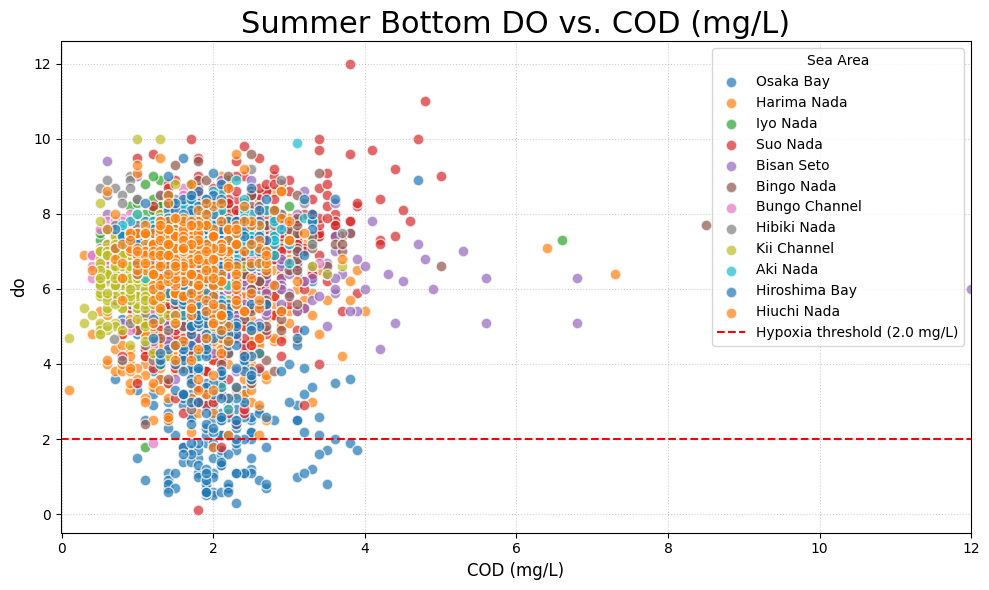

In [33]:
# Make another plot for all the other divisions
summer_bottom_df[nutrient_col] = pd.to_numeric(summer_bottom_df[nutrient_col], errors='coerce')
summer_bottom_df[do_col] = pd.to_numeric(summer_bottom_df[do_col], errors='coerce')

# set fixed manual range (adjust for each nutrient as needed)
x_min, x_max = -0.01, 12.0

plt.figure(figsize=(10,6))

for area in summer_bottom_df['division'].unique():
    subset = summer_bottom_df[summer_bottom_df['division'] == area]
    plt.scatter(
        subset[nutrient_col], 
        subset['do_'], 
        label=area,      # This ensures it shows up in the legend
        # color= , # Assign unique color
        alpha=0.7,       # Transparency
        edgecolors='w',  # White edge makes dots stand out
        s=60             # Dot size
    )

# hypoxia treshold reference line (2mg/L)
plt.axhline(y=2.0, color='red', linestyle='--', linewidth=1.5, label='Hypoxia threshold (2.0 mg/L)')

# get axis and set ranges if available
ax = plt.gca()
ax.set_xlim(x_min, x_max)

# Formatting
xlabel_text = labels.get(nutrient_col, nutrient_col)
ylabel_text = labels.get('do', 'do')

plt.title(f'Summer Bottom DO vs. {xlabel_text}', fontsize=22)
plt.xlabel(xlabel_text, fontsize=12)
plt.ylabel(ylabel_text, fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(title='Sea Area', loc='upper right')

plt.tight_layout()
plt.show()

In [25]:
print("labels mapping:", labels)
print("xlabel_text:", xlabel_text, "ylabel_text:", ylabel_text)

labels mapping: {'tn': 'Total Nitrogen (mg/L)', 'tp': 'Total Phosphorus (mg/L)', 'po4p': 'Phosphate-P (mg/L)', 'cod': 'COD (mg/L)', 'do_': 'Dissolved Oxygen (mg/L)'}
xlabel_text: Phosphate-P (mg/L) ylabel_text: do


Let's try making this again for the winter bottom data

In [44]:
# Filter summer bottom do data
winter_bottom_df = merged_gdf[
    (merged_gdf['season'] == 'Winter') &
    (merged_gdf['saisuipoin'] == 2)
].dropna(subset=['do_']).copy()

Let's also try to compare between the top and bottom water layer.